In [7]:
# Original groups : 정답 묶음 
# Group : 묶음
# Noise : 어디에도 묶이지 않은 data points

import numpy as np  
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

# 데이터 셋 불러오기
spherical = pd.read_csv("./data_sets/spherical_6_2.csv")  # 둥근 묶음 6개
spiral = pd.read_csv("./data_sets/3_spiral.csv")  # 나선 모양의 묶음 3개
jain = pd.read_csv("./data_sets/jain.csv")  # 빽빽한 정도가 다른 묶음 2개
pathbased = pd.read_csv("./data_sets/pathbased.csv")  # 바깥 곡선과 안쪽

for name, data in [("spherical_6_2", spherical), ("3_spiral", spiral), ("jain", jain)]:
    assert list(data.columns) == ["x", "y", "class"], "CSV 열 이름은 x,y,class여야 합니다."
    assert not data.isna().any().any(), "CSV에 비어 있는 값이 있습니다."
    print(f"{name}: 점 {len(data)}개 / 정답 묶음 {data['class'].nunique()}개")


# 시각화 함수 구현
def show_result(data, labels, title, centers=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)
    panels = [(axes[0], data["class"].to_numpy(), "Original groups"),
              (axes[1], labels, title)]  
    for ax, groups, panel_title in panels:
        color_index = 0  
        for group in np.unique(groups):  
            selected = groups == group  
            if group == -1:  # Noise
                ax.scatter(data.loc[selected, "x"], data.loc[selected, "y"],
                           color="black", marker="x", s=28, label="Noise")  
            else:
                ax.scatter(data.loc[selected, "x"], data.loc[selected, "y"],
                           color=plt.cm.tab10(color_index % 10), s=18,
                           label=f"Group {color_index + 1}")  
                color_index += 1  
        ax.set_title(panel_title)  
        ax.set_xlabel("x")  
        ax.set_ylabel("y")  
        ax.set_aspect("equal", adjustable="box")  
        ax.grid(alpha=0.15)  
        ax.legend(fontsize=8, loc="best")  
    if centers is not None:  # K-Means는 중심 표시
        axes[1].scatter(centers[:, 0], centers[:, 1], c="black", marker="+",
                        s=170, linewidths=2, label="Centers")
        axes[1].legend(fontsize=8, loc="best")
    fig.tight_layout()  
    plt.show()


# DBSCAN의 -1은 Noise이므로 묶음 갯수-1로 표시
def show_counts(labels):
    group_count = len(np.unique(labels[labels != -1]))  # 잡음을 빼고 묶음 수를 셉니다.
    noise_count = int(np.sum(labels == -1))  # 어디에도 묶이지 않은 점을 셉니다.
    print(f"만들어진 묶음: {group_count}개 / 잡음: {noise_count}개")  # 결과를 짧게 보여 줍니다.

print("준비 완료. 아래의 실험 1~6을 차례로 실행하세요.")  # 이 셀은 준비만 하고 실험은 아래에서 합니다.

spherical_6_2: 점 300개 / 정답 묶음 6개
3_spiral: 점 312개 / 정답 묶음 3개
jain: 점 373개 / 정답 묶음 2개
준비 완료. 아래의 실험 1~6을 차례로 실행하세요.


실험 1 | K-Means | spherical_6_2.csv | K = 6, 시작 시도=10, 고정값=42
만들어진 묶음: 6개 / 잡음: 0개


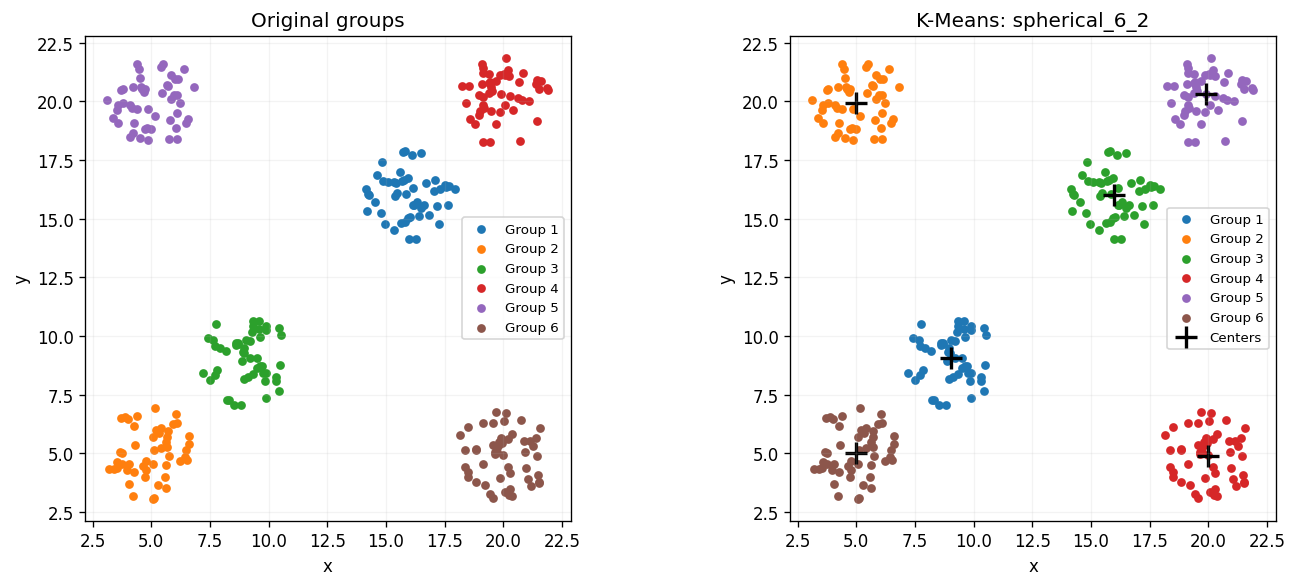

결과: 원래의 둥근 점 무리 6개를 각각 하나의 묶음으로 나눴습니다.
이유: 같은 무리의 점들은 자기 무리 중심에 가깝고, 다른 무리 중심에서는 멉니다.
강점: 떨어진 둥근 묶음을 찾기 쉽고, 각 묶음의 평균 위치도 알 수 있습니다.
주의: K를 미리 지정해야하고 처음 중심을 잘못 잡으면 성능과 결과가 크게 달라질 수 있습니다.


In [4]:
# [실험 1] K-Means가 잘 묶는 사례: spherical_6_2.csv
# 선택 이유: 둥근 점 무리 6개가 떨어져 있어 중심을 기준으로 나누기 좋음
# n_clusters=6: K를 6으로 지정
# n_init=10: 시작 중심을 다르게 해서 10번 시도
# random_state=42: 시작 중심의 랜덤성을 고정

X = spherical[["x", "y"]] 
model = KMeans(n_clusters=6, random_state=42, n_init=10).fit(X)
labels = model.labels_  # 각 점에 붙은 묶음 번호를 꺼냅니다.
print("실험 1 | K-Means | spherical_6_2.csv | K = 6, 시작 시도=10, 고정값=42")
show_counts(labels)  # 몇 개로 묶였는지 확인합니다.
show_result(spherical, labels, "K-Means: spherical_6_2", model.cluster_centers_)
print("결과: 원래의 둥근 점 무리 6개를 각각 하나의 묶음으로 나눴습니다.") 
print("이유: 같은 무리의 점들은 자기 무리 중심에 가깝고, 다른 무리 중심에서는 멉니다.")
print("강점: 떨어진 둥근 묶음을 찾기 쉽고, 각 묶음의 평균 위치도 알 수 있습니다.") 
print("주의: K를 미리 지정해야하고 처음 중심을 잘못 잡으면 성능과 결과가 크게 달라질 수 있습니다.") 

실험 2 | K-Means | 3_spiral.csv | 묶음 수=3, 시작 시도=10, 고정값=42
만들어진 묶음: 3개 / 잡음: 0개


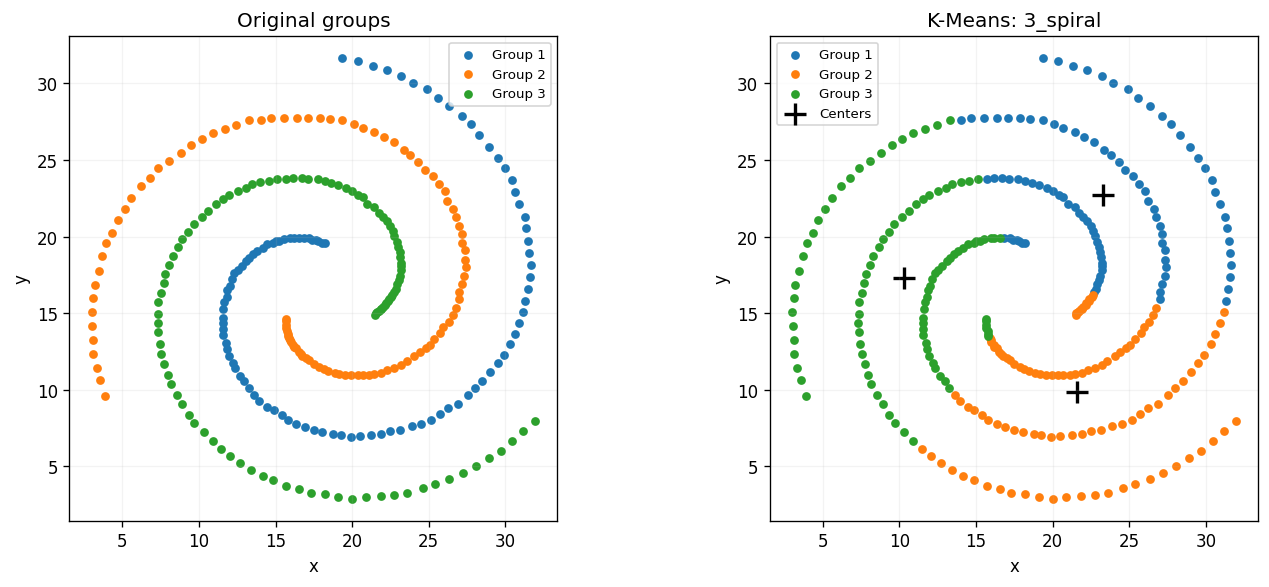

결과: 묶음은 3개지만, 하나의 나선이 여러 묶음으로 잘리고 다른 나선의 점과 섞였습니다.
이유: 나선을 따라 이어지는 관계보다 중심과의 거리를 기준으로 점을 나누기 때문입니다.
약점: 길게 휘거나 서로 감긴 모양은 중심 하나로 표현하기 어렵습니다.


In [5]:
# [실험 2] K-Means가 잘 묶지 못하는 사례: 3_spiral.csv
# 선택 이유: 나선 하나가 길게 이어져 있어 중심 하나까지의 거리만으로 구분하기 힘듬.

X = spiral[["x", "y"]]
model = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)
labels = model.labels_ 
print("실험 2 | K-Means | 3_spiral.csv | 묶음 수=3, 시작 시도=10, 고정값=42")
show_counts(labels) 
show_result(spiral, labels, "K-Means: 3_spiral", model.cluster_centers_)
print("결과: 묶음은 3개지만, 하나의 나선이 여러 묶음으로 잘리고 다른 나선의 점과 섞였습니다.")
print("이유: 나선을 따라 이어지는 관계보다 중심과의 거리를 기준으로 점을 나누기 때문입니다.") 
print("약점: 길게 휘거나 서로 감긴 모양은 중심 하나로 표현하기 어렵습니다.") 

실험 3 | 계층적 완전 연결법 | spherical_6_2.csv | 묶음 수=6, linkage=complete
만들어진 묶음: 6개 / 잡음: 0개


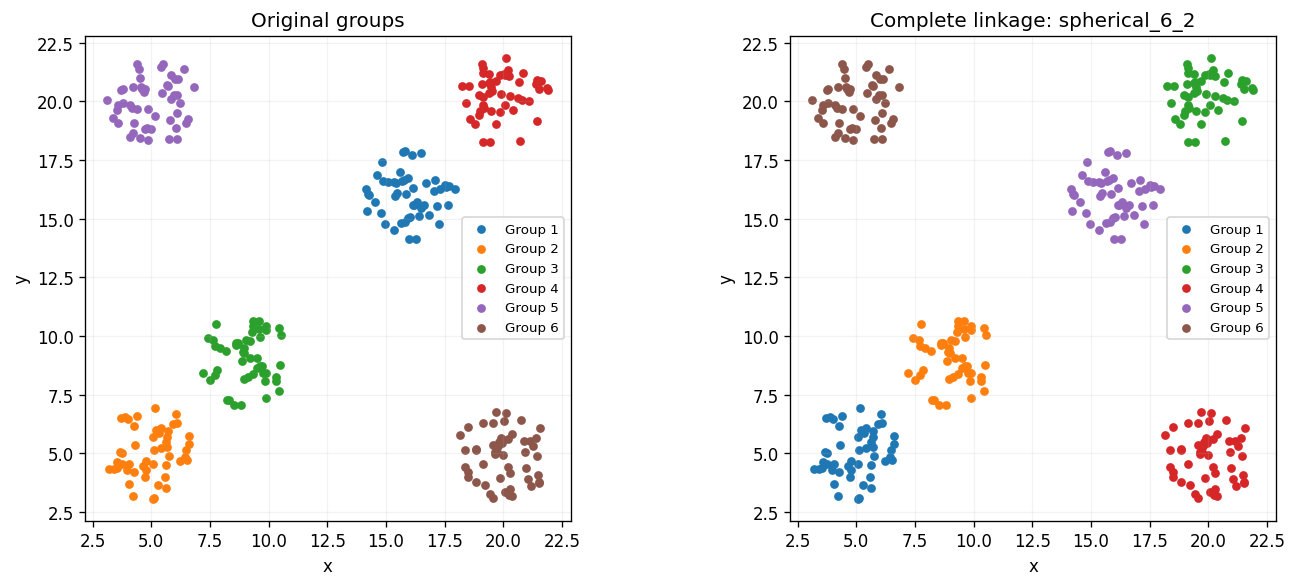

결과: 원래의 둥근 점 무리 6개를 각각 하나로 묶었습니다.
이유: 다른 무리와 합칠 때보다 같은 무리 안에서 합칠 때 가장 먼 점 사이의 거리가 짧습니다.
강점: 묶음의 전체 폭을 살펴 합치므로, 서로 떨어진 조밀한 무리를 찾기 좋습니다.
주의: 여기서는 최종 묶음만 그렸습니다. 합치는 과정 전체를 보려면 나무 모양 그림이 필요합니다.


In [ ]:
# [실험 3] 계층적 완전 연결법이 잘 묶는 사례: spherical_6_2.csv
# 완전 연결법은 두 묶음 사이에서 가장 멀리 떨어진 점 쌍의 거리를 구합니다.
# n_clusters=6: 최종적으로 묶음 6개가 남는 지점의 결과에서 멈춤

X = spherical[["x", "y"]]
model = AgglomerativeClustering(n_clusters=6, linkage="complete").fit(X)  # "complete" : 가장 먼 data point 기준
labels = model.labels_ # 정답 label
print("실험 3 | 계층적 완전 연결법 | spherical_6_2.csv | 묶음 수=6, linkage=complete")
show_counts(labels)  # 묶음 수를 확인합니다.
show_result(spherical, labels, "Complete linkage: spherical_6_2")
print("결과: 원래의 둥근 점 무리 6개를 각각 하나로 묶었습니다.")
print("이유: 다른 무리와 합칠 때보다 같은 무리 안에서 합칠 때 가장 먼 점 사이의 거리가 짧습니다.")
print("강점: 묶음의 전체 폭을 살펴 합치므로, 서로 떨어진 조밀한 무리를 찾기 좋습니다.")


실험 4-1 | pathbased | 연결법=single | 군집 수=3
만들어진 묶음: 3개 / 잡음: 0개
묶음별 점 수: [298   1   1]


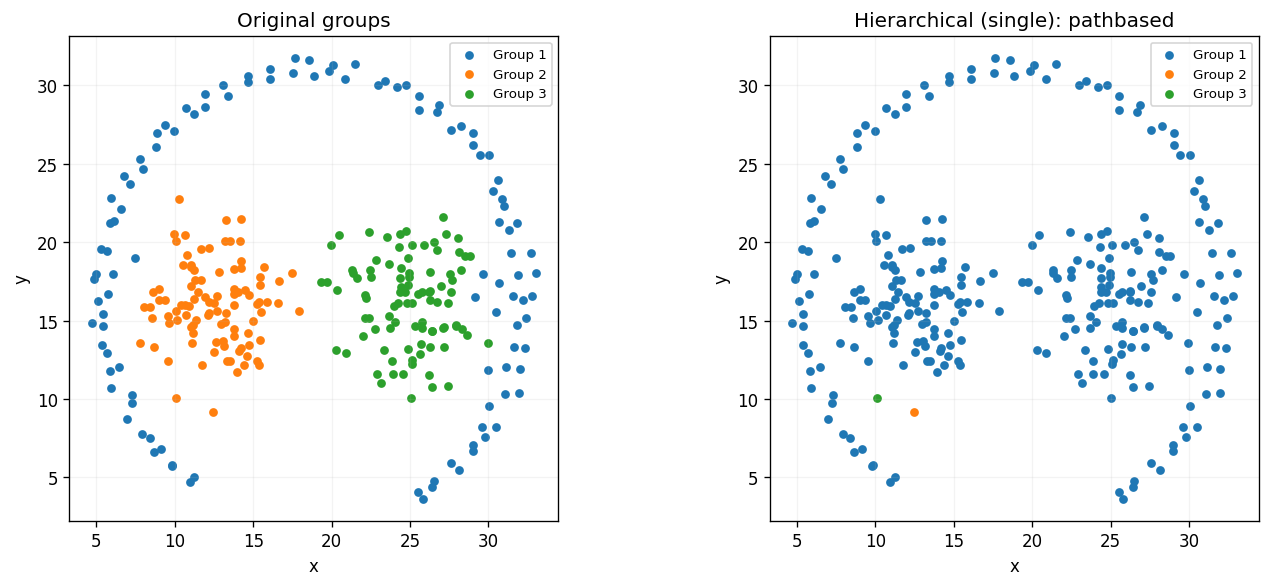


실험 4-2 | pathbased | 연결법=complete | 군집 수=3
만들어진 묶음: 3개 / 잡음: 0개
묶음별 점 수: [153 121  26]


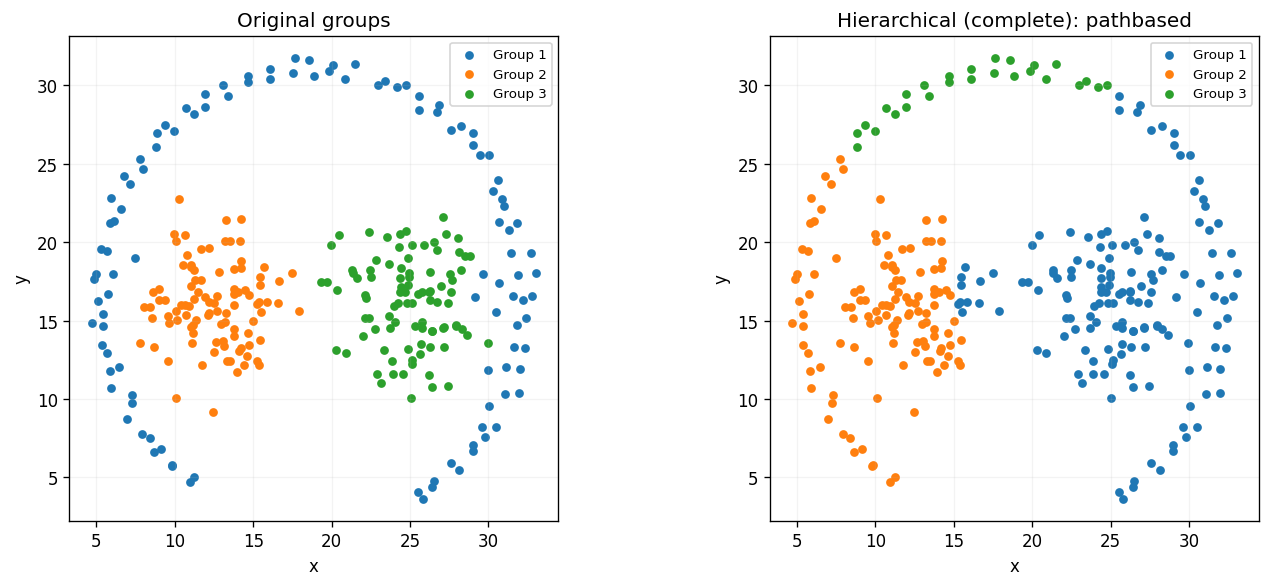


실험 4-3 | pathbased | 연결법=average | 군집 수=3
만들어진 묶음: 3개 / 잡음: 0개
묶음별 점 수: [139  30 131]


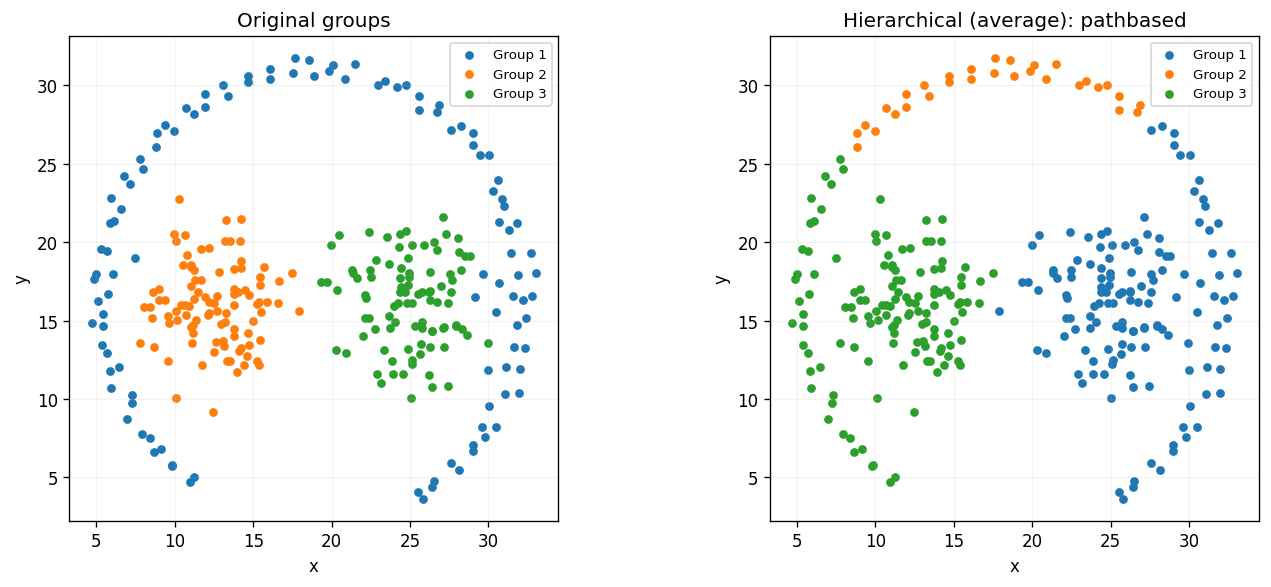


실험 4-4 | pathbased | 연결법=ward | 군집 수=3
만들어진 묶음: 3개 / 잡음: 0개
묶음별 점 수: [138  38 124]


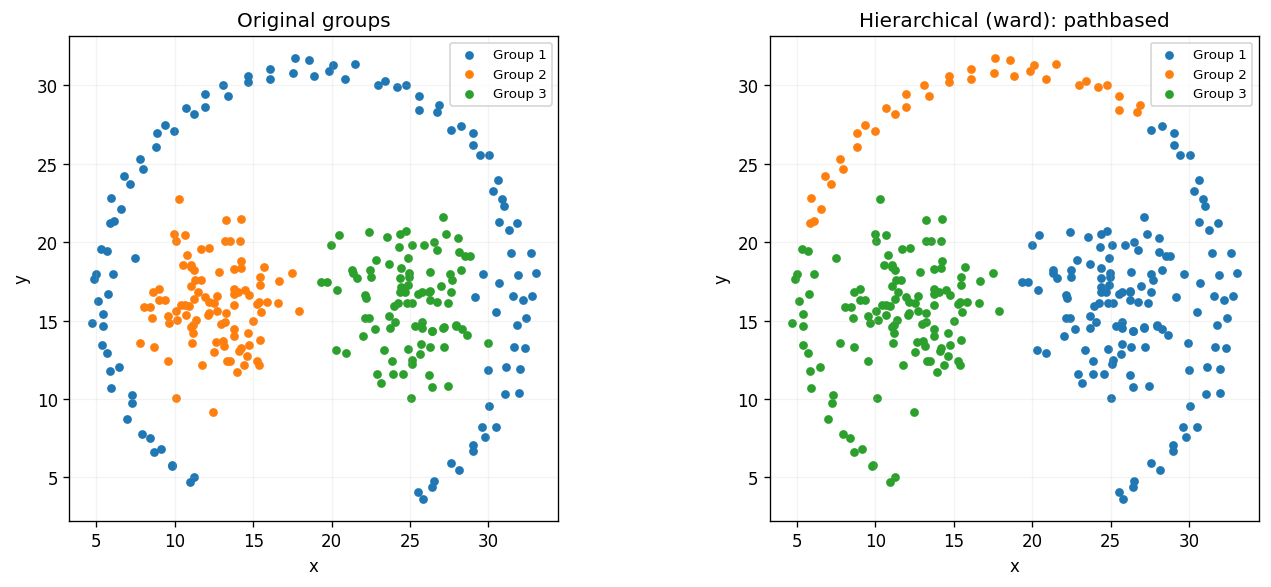


결과: 네 연결법 모두 바깥 곡선과 안쪽 두 무리를 제대로 복원하지 못했습니다.
single은 대부분의 점을 한 묶음으로 합쳤습니다.
나머지 세 방식은 바깥 곡선을 나눠 안쪽 무리와 섞었습니다.

공통 약점: 한 번 합친 묶음을 나중에 다시 나누지 못합니다.
서로 다른 무리가 가까운 부분에서 잘못 합쳐지면, 이후 단계에서 되돌리지 못합니다.


In [9]:
# [실험 4] 계층적 군집화가 잘 묶지 못하는 사례: pathbased

X = pathbased[["x", "y"]]

# 계층적 군집화의 4가지 종류를 모두 테스트
methods = ["single", "complete", "average", "ward"]

for index,method in enumerate(methods):
    model = AgglomerativeClustering(
        n_clusters=3,   #멈출 집합 갯수
        linkage=method
    ).fit(X)

    labels = model.labels_

    print(f"\n실험 4-{index+1} | pathbased | 연결법={method} | 군집 수=3")
    show_counts(labels)
    print("묶음별 점 수:", np.unique(labels, return_counts=True)[1])

    show_result(pathbased, labels, f"Hierarchical ({method}): pathbased")

print("\n결과: 네 연결법 모두 바깥 곡선과 안쪽 두 무리를 제대로 복원하지 못했습니다.")
print("single은 대부분의 점을 한 묶음으로 합쳤습니다.")
print("나머지 세 방식은 바깥 곡선을 나눠 안쪽 무리와 섞었습니다.")

print("\n공통 약점: 한 번 합친 묶음을 나중에 다시 나누지 못합니다.")
print("서로 다른 무리가 가까운 부분에서 잘못 합쳐지면, 이후 단계에서 되돌리지 못합니다.")

실험 5 | DBSCAN | 3_spiral.csv | eps=1.5, min_samples=3
만들어진 묶음: 3개 / 잡음: 0개


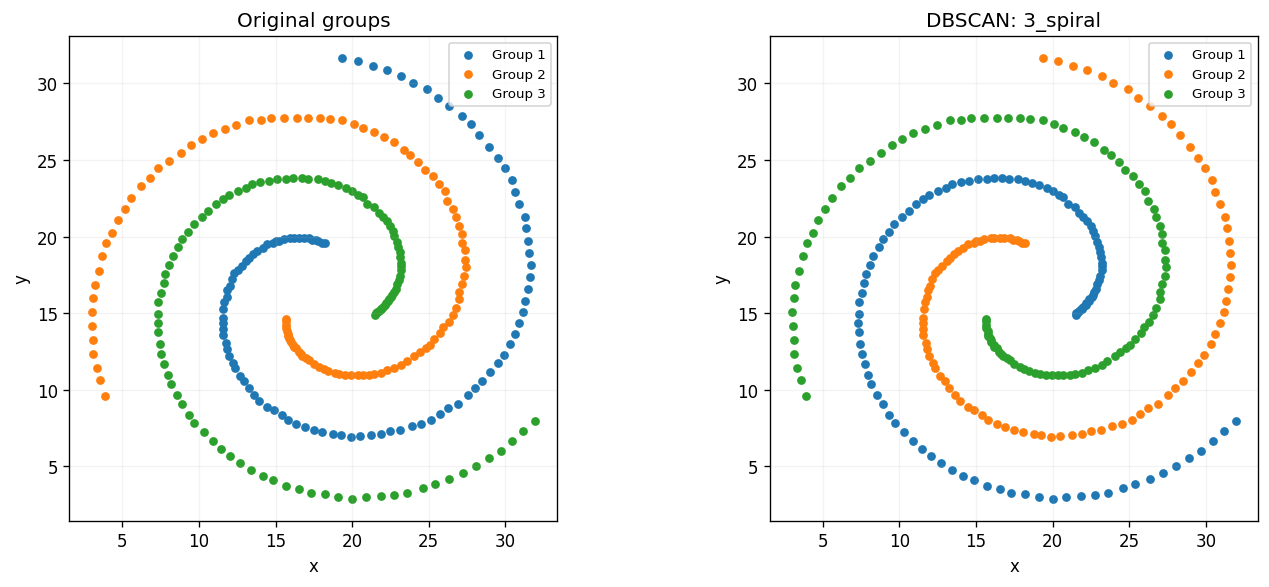

결과: 잡음 없이 나선 3개를 각각 하나의 묶음으로 찾았습니다.
이유: 중심까지의 거리 대신 가까운 점들의 연결을 따라 나선 끝까지 묶을 수 있습니다.
강점: 둥글지 않은 모양도 찾을 수 있고, 묶음 수를 미리 지정하지 않아도 됩니다.
주의: data set에 따라 올바른 eps 값이 다릅니다.


In [13]:
# [실험 5] DBSCAN이 잘 묶는 사례: 3_spiral.csv
# eps=1.5: 거리가 1.5 이하인 점을 이웃으로 포착
# min_samples=3: 자기 자신을 포함해 이웃이 3개 이상이면 묶음을 확장

X = spiral[["x", "y"]]
model = DBSCAN(eps=1.5, min_samples=3).fit(X)  # 묶음 수를 미리 알려주지 않음
labels = model.labels_ 
print("실험 5 | DBSCAN | 3_spiral.csv | eps=1.5, min_samples=3")
show_counts(labels)
show_result(spiral, labels, "DBSCAN: 3_spiral")
print("결과: 잡음 없이 나선 3개를 각각 하나의 묶음으로 찾았습니다.")
print("이유: 중심까지의 거리 대신 가까운 점들의 연결을 따라 나선 끝까지 묶을 수 있습니다.")
print("강점: 둥글지 않은 모양도 찾을 수 있고, 묶음 수를 미리 지정하지 않아도 됩니다.")
print("주의: data set에 따라 올바른 eps 값이 다릅니다.")


실험 6-1 | DBSCAN | jain.csv | eps=2.0, min_samples=5


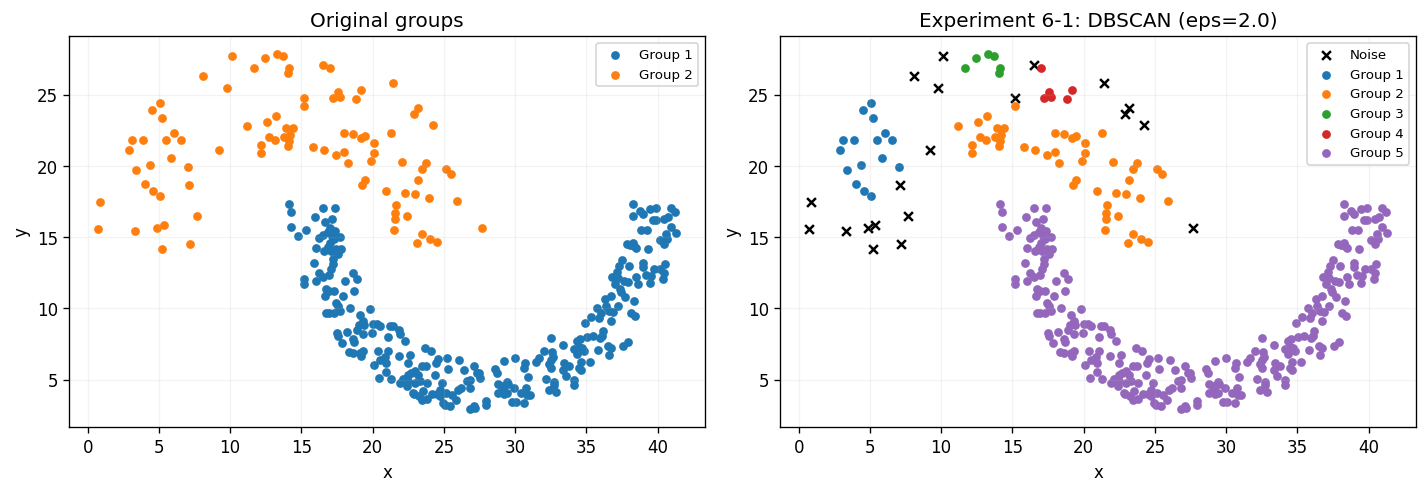


실험 6-2 | DBSCAN | jain.csv | eps=2.5, min_samples=5


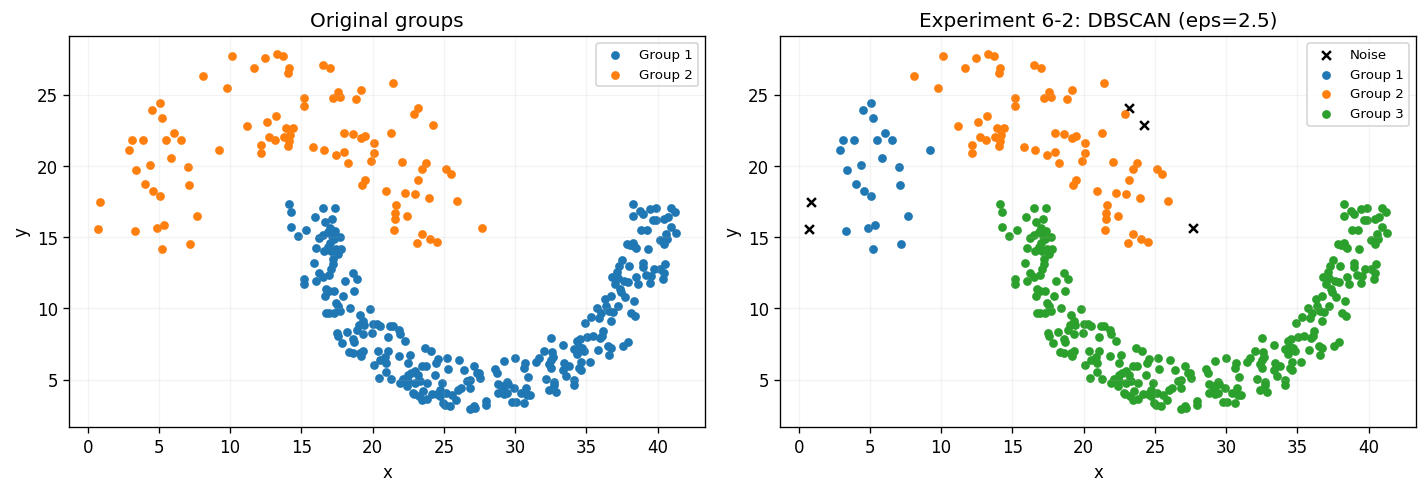


실험 6-3 | DBSCAN | jain.csv | eps=2.6, min_samples=5


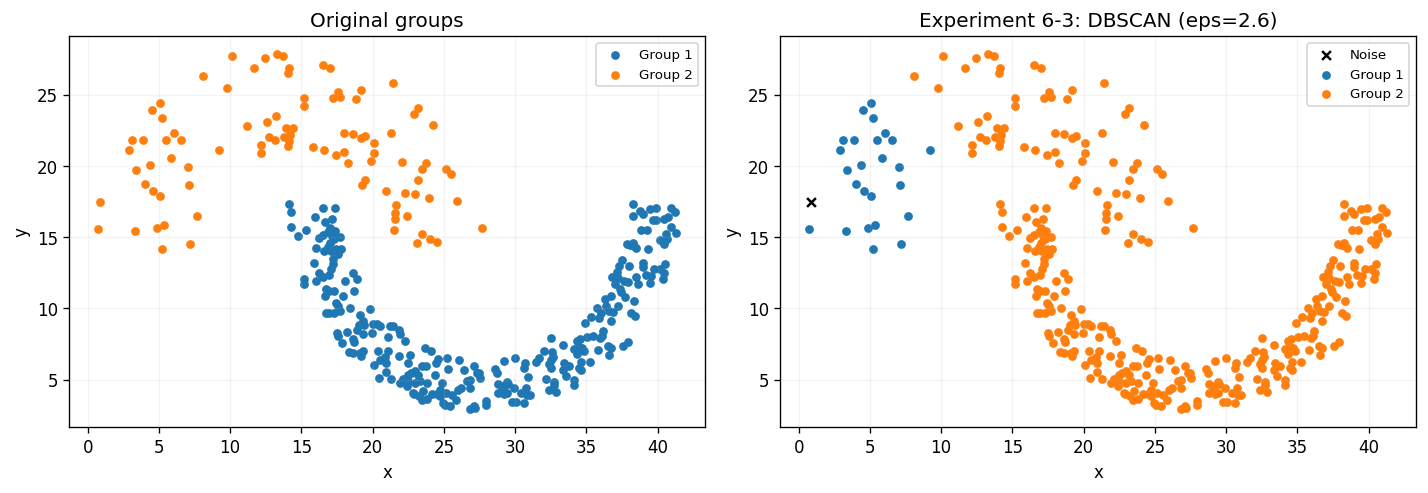


실험 6-4 | DBSCAN | jain.csv | eps=3.0, min_samples=5


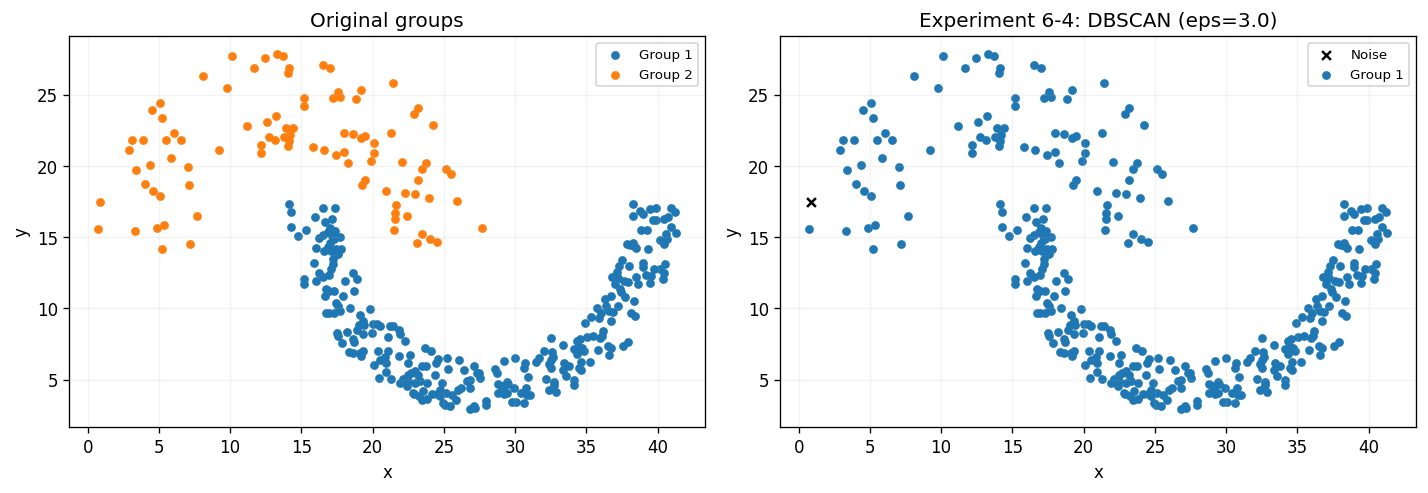


[실험 6 결과]
 실험  eps  묶음 수             묶음별 점 수  잡음 수
6-1  2.0     5 [16, 49, 6, 6, 276]    20
6-2  2.5     3       [24, 68, 276]     5
6-3  2.6     2           [25, 347]     1
6-4  3.0     1               [372]     1

eps를 늘리면 묶음 수가 5개, 3개, 2개, 1개로 줄어듭니다.
eps=2.6에서는 정답과 같은 2개가 나오지만, 올바르게 나뉜 결과는 아닙니다.
정답은 276개와 97개의 두 무리지만, 실행 결과는 347개와 25개의 묶음 및 잡음 1개입니다.
첫 번째 무리 276개에 두 번째 무리의 점 71개가 합쳐졌습니다.

[실험 6 이유]
DBSCAN은 전체 데이터에 같은 eps와 min_samples를 적용합니다.
eps가 작으면 밀도가 낮은 무리의 이웃이 부족해 연결이 끊기거나 잡음으로 처리됩니다.
eps를 늘리면 밀도가 낮은 무리가 온전히 연결되기 전에 다른 무리와 합쳐질 수 있습니다.
따라서 밀도가 다른 무리에는 하나의 거리 기준을 함께 맞추기 어렵습니다.


In [17]:
# [실험 6] 밀도가 다른 데이터에서 eps를 바꾸며 DBSCAN 결과를 비교함
# 한쪽은 점들의 밀도가 높고, 다른 쪽은 밀도가 낮은 데이터임
# min_samples는 5로 고정하고 eps만 변경함
# 잡음은 검은 X로 표시하며, 번호 -1은 일반 묶음 수에서 제외함

X = jain[["x", "y"]]  # 정답을 제외하고 좌표만 입력으로 사용함
rows = []  # 각 설정의 결과를 저장할 목록임

# 네 가지 거리 설정에 대해 군집화와 그래프 출력을 반복함
for index, radius in enumerate([2.0, 2.5, 2.6, 3.0], start=1):
    model = DBSCAN(eps=radius, min_samples=5).fit(X)  # 이웃으로 보는 거리만 바꿔 실행함
    labels = model.labels_  # 각 점의 묶음 번호를 추출함

    # 잡음을 제외한 묶음 수와 묶음별 점 수를 계산함
    group_labels, group_sizes = np.unique(
        labels[labels != -1], return_counts=True
    )
    noise_count = int(np.sum(labels == -1))  # 잡음으로 처리된 점 수를 계산함

    # 현재 실험의 설정을 표시함
    print(f"\n실험 6-{index} | DBSCAN | jain.csv | eps={radius}, min_samples=5")

    # 기존 함수를 사용해 정답과 실행 결과를 나란히 표시함
    show_result(
        jain,
        labels,
        f"Experiment 6-{index}: DBSCAN (eps={radius})"
    )

    # 마지막에 한 번에 비교할 수 있도록 결과를 기록함
    rows.append({
        "실험": f"6-{index}",
        "eps": radius,
        "묶음 수": len(group_labels),
        "묶음별 점 수": str(group_sizes.tolist()),
        "잡음 수": noise_count
    })

# 실험 6 전체의 결과를 표로 정리함
print("\n[실험 6 결과]")
print(pd.DataFrame(rows).to_string(index=False))

print("\neps를 늘리면 묶음 수가 5개, 3개, 2개, 1개로 줄어듭니다.")
print("eps=2.6에서는 정답과 같은 2개가 나오지만, 올바르게 나뉜 결과는 아닙니다.")
print("정답은 276개와 97개의 두 무리지만, 실행 결과는 347개와 25개의 묶음 및 잡음 1개입니다.")
print("첫 번째 무리 276개에 두 번째 무리의 점 71개가 합쳐졌습니다.")

# 실험 6 전체에서 나타난 문제의 원인을 설명함
print("\n[실험 6 이유]")
print("DBSCAN은 전체 데이터에 같은 eps와 min_samples를 적용합니다.")
print("eps가 작으면 밀도가 낮은 무리의 이웃이 부족해 연결이 끊기거나 잡음으로 처리됩니다.")
print("eps를 늘리면 밀도가 낮은 무리가 온전히 연결되기 전에 다른 무리와 합쳐질 수 있습니다.")
print("따라서 밀도가 다른 무리에는 하나의 거리 기준을 함께 맞추기 어렵습니다.")